# Lab02 — Dự báo doanh thu FMCG theo tuần

Notebook đọc lại kết quả cùng lượt FMCG đã hoàn tất. Nguồn và mô hình được xác định từ models/selection.json. Mục tiêu Revenue được tính bằng price_unit × units_sold và cộng theo sku/tuần.

## 1. Mục tiêu và thiết lập

Dự báo Revenue của SKU tuần kế tiếp. Bốn thuật toán tự cài gồm Ridge, Decision Tree, Random Forest và Gradient Boosting. Chọn bằng selection_rmse, test đánh giá cuối.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yaml,joblib

repo=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p / "Lab02/src/config.yaml").is_file())
if str(repo) not in sys.path:
    sys.path.insert(0,str(repo))
from Lab02.src.preprocessing import LAB,FEATURES,build_preprocessor
from Lab02.src.evaluate import metrics
from Lab02.src.train import train_model

published=json.loads((LAB / "models/selection.json").read_text())
run=LAB / "results/runs" / published["run_id"]
manifest=json.loads((run / "run.json").read_text())
if manifest["status"]!="success":
    raise RuntimeError("Select a completed run.")
config=yaml.safe_load((run / "config.yaml").read_text())
selected=json.loads((run / "tuning/selection.json").read_text())
print("Reference run:",run.name)
print("Winner selected before test:",published["winner"])
print(json.dumps(config,ensure_ascii=False,indent=2))


Reference run: 2026-11-24_13-01-41
Winner selected before test: gradient_boosting
{
  "data": {
    "encoding": "utf-8",
    "min_active_weeks": 6,
    "path": "data/raw/FMCG_2022_2024.csv",
    "schema": "fmcg_weekly",
    "top_products": 20
  },
  "experiment": {
    "forecast": "rolling_one_week_ahead",
    "product_scope": "fixed_top_products_selected_from_full_train",
    "selection": "mean_rmse_three_expanding_folds_and_validation"
  },
  "models": {
    "decision_tree": [
      {
        "feature_set": "basic",
        "max_depth": 5,
        "min_samples_leaf": 10
      },
      {
        "feature_set": "trend",
        "max_depth": 5,
        "min_samples_leaf": 10
      },
      {
        "feature_set": "basic",
        "max_depth": 10,
        "min_samples_leaf": 20
      },
      {
        "feature_set": "trend",
        "max_depth": 10,
        "min_samples_leaf": 20
      },
      {
        "feature_set": "trend",
        "max_depth": 4,
        "min_samples_leaf": 20
   

**Kết quả và nhận xét.** Cấu hình trên là bản snapshot của lần chạy, có thể khác YAML đang chỉnh sửa trong src. Toàn bộ ô sau dùng cùng thư mục run.

## 2. Dữ liệu và EDA

Nguồn FMCG_2022_2024.csv, 190.757 dòng và 30 SKU. Tổng hợp Revenue qua channel, region và pack_type. Loại 3 dòng units_sold âm, giữ bán 0. Tuần từ thứ Hai đến Chủ nhật.

Source rows: 190757
      date    sku    brand   segment category  channel     region pack_type  price_unit  promotion_flag  delivery_days  stock_available  delivered_qty  units_sold
2022-01-21 MI-006 MiBrand1 Milk-Seg3     Milk   Retail PL-Central Multipack        2.38               0              1              141            128           9
2022-01-21 MI-006 MiBrand1 Milk-Seg3     Milk   Retail   PL-North    Single        1.55               1              3                0            129           0
2022-01-21 MI-006 MiBrand1 Milk-Seg3     Milk   Retail   PL-South    Carton        4.00               0              5              118            161           8
2022-01-21 MI-006 MiBrand1 Milk-Seg3     Milk Discount PL-Central    Single        5.16               0              2               81            114           7
2022-01-21 MI-006 MiBrand1 Milk-Seg3     Milk Discount   PL-North    Single        7.66               0              4              148            204          12
da

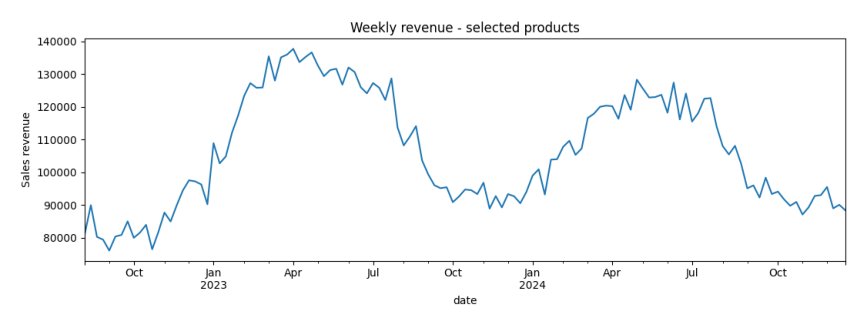

In [2]:
raw=pd.read_csv(LAB / config["data"]["path"],encoding=config["data"]["encoding"],
                dtype={"sku":str})
print("Source rows:",len(raw))
print(raw.head().to_string(index=False))
print(raw.isna().sum().to_string())
summary=json.loads((run / "preprocessing/summary.json").read_text())
print(json.dumps(summary,ensure_ascii=False,indent=2))
plt.figure(figsize=(12,4))
plt.imshow(plt.imread(run / "figures/daily_sales.png"))
plt.axis("off")
plt.show()


**Nhận xét.** Revenue dùng đơn vị price_unit nguồn. Các giá trị giá, khuyến mãi, tồn kho và giao hàng của tuần tương lai chưa được đưa vào đầu vào. Phạm vi gồm 20 SKU được chọn từ train.

## 3. Chia thời gian và đặc trưng

Các tập nối tiếp theo tuần. Lag và rolling chỉ lấy lịch sử trước tuần dự báo. CSV công khai dùng sku và Revenue, được ánh xạ về tên nội bộ khi gọi mô hình.

In [3]:
frames={name:pd.read_csv(run / "preprocessing" / f"{name}.csv",dtype={"StockCode":str},float_precision="round_trip").rename(columns={"sku":"StockCode","Revenue":"sales"})
        for name in ["train","validation","test"]}
train,validation,test=(frames[name] for name in ["train","validation","test"])
assert train.date.max()<validation.date.min()
assert validation.date.max()<test.date.min()
overview=pd.DataFrame([{"split":name,"rows":len(frame),"start":frame.date.min(),"end":frame.date.max()}
                       for name,frame in frames.items()])
print(overview.to_string(index=False))
processor=build_preprocessor("basic")
X=processor.fit_transform(train[FEATURES])
V=processor.transform(validation[FEATURES])
print("Training shape:",X.shape,"| Validation shape:",V.shape)
print("Feature columns:",FEATURES)


     split  rows      start        end
     train  1260 2022-08-08 2023-10-16
validation   620 2023-10-23 2024-05-20
      test   620 2024-05-27 2024-12-23
Training shape: (1260, 27) | Validation shape: (620, 27)
Feature columns: ['StockCode', 'lag_1', 'lag_7', 'mean_7', 'mean_28', 'month', 'weekday', 'day_of_year', 'median_7', 'median_28', 'std_7', 'std_28', 'zero_days_28', 'same_weekday_mean_4']


**Nhận xét.** Bỏ 28 tuần đầu thiếu lịch sử làm số mẫu khác tỷ lệ 60/20/20. Đánh giá rolling một bước sử dụng doanh thu thực tế các tuần trước. Tập test không mô phỏng dự báo đệ quy nhiều tuần.

## 4. Baseline trên validation

So sánh trung bình chung, độ trễ 7 tuần, trung bình 7/28 tuần, trung bình các mốc 7/14/21/28 tuần và trung bình theo SKU. Baseline được tính theo lịch sử có sẵn.

In [4]:
baseline_predictions={
    "mean":np.repeat(train.sales.mean(),len(validation)),
    "last_week":validation.lag_7.to_numpy(),
    "rolling_7":validation.mean_7.to_numpy(),
    "rolling_28":validation.mean_28.to_numpy(),
    "weekday_4":validation.same_weekday_mean_4.to_numpy(),
    "product_mean":validation.StockCode.map(train.groupby("StockCode").sales.mean()).to_numpy(),
}
baseline_validation=pd.DataFrame([{"baseline":name,**metrics(validation.sales,prediction)}
                                 for name,prediction in baseline_predictions.items()])
print(baseline_validation.to_string(index=False))


    baseline         mae          mse        rmse        r2
        mean 1125.553880 1.886792e+06 1373.605487 -0.001904
   last_week  845.484065 1.182020e+06 1087.207657  0.372336
   rolling_7  602.824182 6.017066e+05  775.697478  0.680488
  rolling_28 1117.310810 1.897108e+06 1377.355556 -0.007382
   weekday_4 1263.241847 2.445197e+06 1563.712445 -0.298422
product_mean 1073.086540 1.787135e+06 1336.837526  0.051015


**Nhận xét.** Baseline giúp kiểm tra mức cải thiện thực tế. Cấu hình phức tạp cần được đối chiếu trên cùng giai đoạn, không chỉ dựa vào điểm của một mô hình riêng.

## 5. Tuning và walk-forward

Mỗi ứng viên được huấn luyện trên ba cửa sổ mở rộng trong train và trên toàn bộ train để chấm validation cuối. selection_rmse lấy trung bình RMSE bốn giai đoạn. tune() dùng train_model() trong src/train.py, fit lại bộ tiền xử lý cho từng lượt.

In [5]:
trials=pd.read_csv(run / "tuning/validation_metrics.csv")
folds=pd.read_csv(run / "tuning/walk_forward_metrics.csv")
print(trials.to_string(index=False))
print(folds.head(12).to_string(index=False))
assert (pd.to_datetime(folds.train_end)<pd.to_datetime(folds.validation_start)).all()


            model                                                                             parameters        mae           mse       rmse       r2  selection_rmse  walk_forward_rmse_std
linear_regression     {'alpha': 1.0, 'learning_rate': 0.1, 'n_iterations': 3000, 'feature_set': 'basic'} 599.937747 585059.875871 764.892068 0.689328     1011.898255             426.550617
linear_regression     {'alpha': 1.0, 'learning_rate': 0.1, 'n_iterations': 3000, 'feature_set': 'trend'} 599.653071 584553.085179 764.560714 0.689597     1021.333387             444.328548
linear_regression    {'alpha': 10.0, 'learning_rate': 0.1, 'n_iterations': 3000, 'feature_set': 'basic'} 603.034460 589505.831722 767.792831 0.686967      950.746646             315.438416
linear_regression    {'alpha': 10.0, 'learning_rate': 0.1, 'n_iterations': 3000, 'feature_set': 'trend'} 600.668143 585399.150033 765.113815 0.689148      959.377618             334.210532
linear_regression    {'alpha': 1.0, 'learning_rate': 0.

**Nhận xét.** basic, trend và robust thử các bộ đặc trưng khác nhau. Danh mục SKU chọn từ train tổng được giữ cố định qua các fold. Các tên kế thừa như lag_7 và mean_28 có đơn vị tuần.

## 6. Lựa chọn cuối

Mỗi họ thuật toán giữ cấu hình selection_rmse thấp nhất. Mô hình demo được chọn từ cùng tiêu chí trước khi chấm test. Các cấu hình cuối được fit lại trên train cộng validation.

In [6]:
print(json.dumps(selected,ensure_ascii=False,indent=2))
best=trials.sort_values("selection_rmse",kind="stable").drop_duplicates("model")
print(best[["model","parameters","selection_rmse"]].to_string(index=False))
print("Published winner:",published["winner"])


{
  "linear_regression": {
    "alpha": 10.0,
    "learning_rate": 0.1,
    "n_iterations": 3000,
    "feature_set": "robust"
  },
  "decision_tree": {
    "max_depth": 10,
    "min_samples_leaf": 20,
    "feature_set": "trend"
  },
  "random_forest": {
    "n_estimators": 80,
    "max_depth": 14,
    "min_samples_leaf": 10,
    "feature_set": "robust"
  },
  "gradient_boosting": {
    "n_estimators": 100,
    "max_depth": 2,
    "learning_rate": 0.05,
    "feature_set": "trend"
  }
}
            model                                                                             parameters  selection_rmse
gradient_boosting   {'n_estimators': 100, 'max_depth': 2, 'learning_rate': 0.05, 'feature_set': 'trend'}      860.639569
    random_forest {'n_estimators': 80, 'max_depth': 14, 'min_samples_leaf': 10, 'feature_set': 'robust'}      910.938236
linear_regression   {'alpha': 10.0, 'learning_rate': 0.1, 'n_iterations': 3000, 'feature_set': 'robust'}      940.377385
    decision_tree         

**Nhận xét.** Gradient Boosting được chọn bằng validation. Các dự đoán Revenue âm được cắt về 0 khi xuất kết quả.

## 7. Đánh giá test, dự đoán và phần dư

Nạp mô hình của đúng run, tính lại chỉ số bằng hàm tự cài và đối chiếu metrics.csv đã lưu.

                model  fit_seconds         mae          mse        rmse        r2
    linear_regression     0.143864  553.385393 4.795127e+05  692.468528  0.670385
        decision_tree     0.527825  571.789421 5.202455e+05  721.280481  0.642385
        random_forest    13.367193  532.781199 4.505469e+05  671.227910  0.690296
    gradient_boosting     2.794317  546.243872 4.708371e+05  686.175722  0.676349
        mean_baseline     0.000000 1005.879762 1.507721e+06 1227.892816 -0.036401
   last_week_baseline     0.000000  910.354806 1.373676e+06 1172.039201  0.055741
   rolling_7_baseline     0.000000  606.089009 5.953779e+05  771.607342  0.590740
  rolling_28_baseline     0.000000 1057.040645 1.661168e+06 1288.863006 -0.141880
   weekday_4_baseline     0.000000 1208.441383 2.180317e+06 1476.589492 -0.498741
product_mean_baseline     0.000000  973.937722 1.419391e+06 1191.381943  0.024317
Recomputed winner metrics: {'mae': 546.2438721198508, 'mse': 470837.12091438397, 'rmse': 686.17572

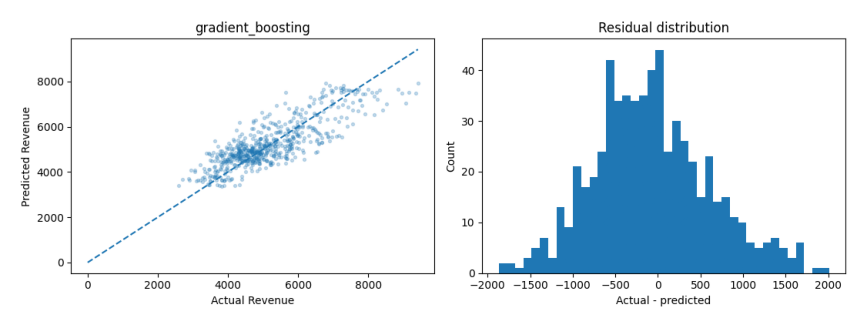

In [7]:
results=pd.read_csv(run / "evaluation/metrics.csv")
print(results.to_string(index=False))
winner=published["winner"]
model=joblib.load(run / "models" / f"{winner}.joblib")
predicted=np.maximum(0,model.predict(test[FEATURES]))
recomputed=metrics(test.sales,predicted)
saved=results.loc[results.model==winner].iloc[0]
for name,value in recomputed.items():
    assert np.isclose(value,saved[name])
print("Recomputed winner metrics:",recomputed)
plt.figure(figsize=(12,4))
plt.imshow(plt.imread(run / "figures" / f"{winner}.png"))
plt.axis("off")
plt.show()
error_files=sorted((run / "evaluation").glob(f"{winner}*largest_errors.csv"))
if error_files:
    print(pd.read_csv(error_files[0]).head(10).to_string(index=False))


**Nhận xét.** Phần dư dương là dự báo thiếu Revenue. Random Forest có điểm test tốt nhất trong lượt tham chiếu, còn Gradient Boosting vẫn là mô hình được chọn bằng validation.

## 8. Kết luận và đầu ra

Notebook đọc lại kết quả. Muốn thực nghiệm cấu hình mới, sửa YAML và chạy pipeline để tạo thư mục riêng. Pipeline lưu model, preprocessing, tuning, evaluation, figures, config và lịch sử cùng run_id.

In [8]:
baseline_rmse=float(results.loc[results.model=="mean_baseline","rmse"].iloc[0])
winner_rmse=float(saved["rmse"])
print("Model selected on development:",winner)
print("Test RMSE improvement vs mean baseline (%):",100*(baseline_rmse-winner_rmse)/baseline_rmse)
print("Test R2:",float(saved["r2"]))
print("Run:",run)
print("This notebook writes no experimental artifacts into the reference run.")


Model selected on development: gradient_boosting
Test RMSE improvement vs mean baseline (%): 44.11762063627163
Test R2: 0.6763485039705748
Run: E:\ML_Nhóm6\Lab02\results\runs\2026-11-24_13-01-41
This notebook writes no experimental artifacts into the reference run.


**Kết luận.** Kết quả áp dụng cho 20 SKU, quy ước tuần trống Revenue=0 và cần 28 tuần lịch sử. Có thể cải thiện đặc trưng bằng các độ trễ phù hợp hơn, nhưng phải chọn trên validation và đánh giá ở giai đoạn độc lập.